In [ ]:
---
project_title: petadex_database_paper
experiment_name: clustering_distributions
author: Thomas Quigley
type: experiment
date_created: 2025-06-25
progress: Finished
date_finished: 2026-08-11
---

# Creating a Total Plastic Production Graph
> **Author:** Thomas Quigley\
> **Date Started:** June 25th, 2025\
> **Date Finished:** June 27th, 2025\
> **Date Updated:** August 11th, 2026\
> **Input:** All of the data prior to 2015 is from [Geyer, 2017](https://www.science.org/doi/10.1126/sciadv.1700782), while the rest, including predictions are from [Pottinger, 2024](https://www.science.org/doi/10.1126/science.adr3837).

---

## 1. Objective

The goal of this notebook is to generate a plot that shows the total plastic production over time, including recycling, incineration and disposal rates. This figure provides the story that the amount of plastic waste entering the environment is near exponential, which is an issue.

## 2. Experiment
### 2.1. Geyer 2017 Wrangling
---
In the supplmentary files, it gives a table of yearly production values from 1950 to 2015. I summed the values from this production each year to produce the culminative plastic produced. 

There was no data for recycling and incineration data within the supplementary files, but they say in the paper: "The resulting global nonfiber recycling rate increased at a constant 0.7% per annum (p.a) between 1990 and 2014." and "The global nonfiber incineration rate has grown more unevenly but, on average, increased 0.7 p.a between 1980 and 2014." This linear trend is the simplification of the resin (nonfiber) data accumulated from across the world. An issue with using this data, is that it's only nonfiber plastics (most plastic we talk about). I will use this linear trend to encompass the rates, as I don't have better data. 

Since they mention that the average in-use time of a plastic is 1 year, I will take the produced plastic from the prior year (what is now going to be waste) and multiple this by the recycling and incinerating rate of that year. I will do this 1 year buffer, as it isn't honest to have the plastic produced immediately be recycled.


They mention that from 1990 to 2014 the rate of recycling increases by 0.7% per year. I will assume they mean that 1990 will have 0.7% recycling. The same goes with incineration.


### 2.2. Pottinger 2024 Wrangling
---
I took the yearly production rate from the supplementary data and added it to the 2017 data. I added all of the values measured from 2015 to 2022, then the predicted values from 2022 to 2050.

The recycling rates of this added data follows the linear prediction of recycling rates from Geyer 2017 for simplicity reasons.

### 2.3. Total Carbon Weight of Plastic
---
According to [Geyer, 2017](https://pmc.ncbi.nlm.nih.gov/articles/PMC5517107/) the most common type of plastic is PE (36.3%), PP (21.0%), PVC (11.8%), PET (10.2%), PUR (8.2%), PS (7.6%) and rest (4.9%). I am going to get the ratio of carbon to total MW for each of these platics, and according to the ratio in the produced, get the average carbon percentage in the weight. PUR is a group of plastics so I will ignore it (R side chains differ), as well as I will ignore the rest of plastics.

PE: <img src="images/PE_monomer.jpg" width="300">\
PET: <img src="images/PET_monomer.jpg" width="300">\
PP: <img src="images/PP_monomer.jpg" width="300">\
PS: <img src="images/PS_monomer.jpg" width="300">\
PVC: <img src="images/PVC_monomer.png" width="300">

**All of these calculations were taken for 2024 data.** To calculate the % of carbon in a plastic, I took the monomer (not including ends) and used took the C MW / total MW. This would output me a percentage of the mass that is within carbon. I then calculated the total mass of carbon trapped within that given plastic, took the adjusted sum of these (since PUR and rest was not included) to get the total of **9.331 billion tonnes of carbon within plastic produced**. After adjusting for the total left in the environment (total -recycled -incinerated), there is **6.347 billion tonnes of carbon trapped within plastic in the environment**. This number included the amount in-use. There is [2.589 billion tonnes of carbon within animals](https://www.visualcapitalist.com/all-the-biomass-of-earth-in-one-graphic/), which means that there is **2.45 times more carbon trapped within plastic then within animals**.

### 2.4. Plot the plastic production in a line plot
---
The following code is to generate a plot that shows the total amount of plastics produced. I want each of the lines (produced, recycled, and incinerated) to have their areas coloured in.


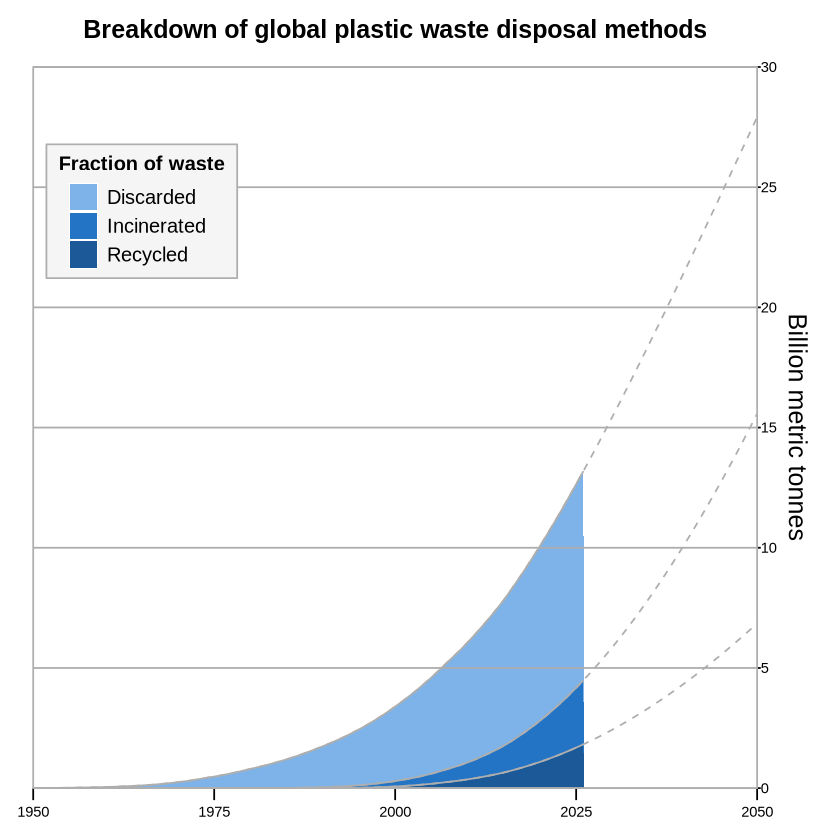

In [5]:
# ——————— INSTALL PACKAGES FOR OTHER PACKAGE INSTALLS ——————— #
if (!require("pacman")) install.packages("pacman")

##### ——————— CRAN PACKAGES ——————— #####
packages <- c("ggplot2", "svglite", "ggpattern", "dplyr", "tidyr")
pacman::p_load(char = packages)

# ———— GRAB THE DATA ———— #
plastic <- read.csv("input/product-to-year.csv")
plastic$recyc_inc <- plastic$Total.Recycled + plastic$Total.Incinerated
plastic$environ <- plastic$Total.Produced - plastic$Total.Recycled - plastic$Total.Incinerated
plastic$Year <- as.numeric(plastic$Year)
plastic$Period <- ifelse(plastic$Year <= 2026, "Past", "Future")

# Prepare data for stacked area
plastic_long <- plastic %>%
  filter(Period == "Past") %>%
  select(Year, `Discarded` = environ, Incinerated = Total.Incinerated, Recycled = Total.Recycled) %>%
  pivot_longer(-Year, names_to = "Type", values_to = "Value")

plastic_long$Type <- factor(plastic_long$Type, levels = c("Discarded", "Incinerated", "Recycled"))

# ———— SET UP THE COLOURS ———— #
DISCARDED = "#7db3e8ff"
INCINERATED = "#2374c5ff"
RECYCLED = "#1b5998ff"
BACKGROUND = "#0f172aff"
LINES = "#aeaeaeff"
TEXT = "#f5f5f5ff"

fill_colors <- c(
  "Discarded" = DISCARDED,
  "Incinerated" = INCINERATED,
  "Recycled" = RECYCLED
)

# Define custom tick positions and tick length
x_ticks <- seq(1950, 2050, by = 25)
y_ticks <- seq(0, 30, by = 5)
tick_length <- 0.5  # Length of custom ticks in plot units

# Custom x-axis ticks
x_tick_segments <- geom_segment(
  data = data.frame(x = x_ticks),
  aes(x = x, xend = x, y = 0, yend = 0 - tick_length),
  inherit.aes = FALSE,
  color = "black"
)

# Custom y-axis ticks (on the right side)
y_tick_segments <- geom_segment(
  data = data.frame(y = y_ticks),
  aes(x = 2050, xend = 2050 + tick_length, y = y, yend = y),
  inherit.aes = FALSE,
  color = "black"
)

# Build the plot
p <- ggplot() +
  # Area plot
  geom_area(data = plastic_long, aes(x = Year, y = Value, fill = Type)) +

  # Reference grid lines
  geom_hline(yintercept = y_ticks, color = "#adacac", size = 0.5) +

  # Total Produced
  geom_line(data = filter(plastic, Period == "Past"), aes(x = Year, y = Total.Produced), color = LINES, size = 0.5) +
  geom_line(data = filter(plastic), aes(x = Year, y = Total.Produced), color = LINES, size = 0.5, linetype = "dashed") +
  
  # Recycled + Incinerated
  geom_line(data = filter(plastic, Period == "Past"), aes(x = Year, y = recyc_inc), color = LINES, size = 0.5) +
  geom_line(data = filter(plastic), aes(x = Year, y = recyc_inc), color = LINES, size = 0.5, linetype = "dashed") +
  
  # Recycled only
  geom_line(data = filter(plastic, Period == "Past"), aes(x = Year, y = Total.Recycled), color = LINES, size = 0.5) +
  geom_line(data = filter(plastic), aes(x = Year, y = Total.Recycled), color = LINES, size = 0.5, linetype = "dashed") +

  # Custom tick marks
  x_tick_segments +
  y_tick_segments +

  # Scales and coordinates
  scale_fill_manual(values = fill_colors) +
  scale_x_continuous(breaks = x_ticks, expand = c(0, 0)) +
  scale_y_continuous(breaks = y_ticks, position = "right", expand = c(0, 0)) +
  coord_cartesian(xlim = c(1950, 2050), ylim = c(0, 30), expand = FALSE, clip = "off") +

  # Labels and theme
  labs(
    title = "Breakdown of global plastic waste disposal methods",
    x = NULL,
    y = "Billion metric tonnes",
    fill = "Fraction of waste"
  ) +
  theme_classic() +
  theme(
    plot.title = element_text(size = 15, face = "bold", hjust = 0.5, vjust = 3),
    axis.title.y = element_text(size = 15),
    legend.text = element_text(size = 12),
    legend.title = element_text(size = 12, hjust = 0.5, face = "bold"),
    legend.position = c(0.15, 0.80),
    legend.background = element_rect(fill = TEXT, color = LINES),
    axis.text.x = element_text(vjust = -2),
    axis.ticks = element_blank(),         # disable default ticks
    axis.line = element_blank(),          # disable axis lines
    panel.border = element_rect(colour = LINES, fill = NA, linewidth = 0.5),
    panel.grid = element_blank(),
    plot.margin = margin(20, 20, 20, 20)
  )

# Save to file
ggsave("images/plastic-disposal_plot.svg", plot = p, dpi = 300, width = 8, height = 5)
p

# 2026 Update
I have updated the above plot to show 2026 data, which ends up being the following. The carbon mass of life info comes from [PNAS](https://www.pnas.org/doi/10.1073/pnas.1711842115)

| measurement | GiTonnes |
| ----------- | -------- |
| Total       | 13.2     |
| Recycled    | 1.8      |
| Incinerated | 2.6      |
| Carbon Mass | 10.2     |
| Animal      | 2        |
| Archea      | 7        |
| Protists    | 4        |
| Fungi       | 12       | 
| Bacteria    | 70       |
| Plants      | 450      |